# Pandas 2: Plotting

**Seong Cho** · ACME Data Science Essentials, Lab 8

**Lab objective:** use the plotting tools pandas wraps around matplotlib to compare parts of a data set, explore it as a whole, and present clear, labeled, honestly sourced visualizations.

<sub>Lab specification from the *Data Science Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). The course's lab template had only a one-line stub, so problem statements are quoted from the spec's January 2019 edition, which matches the version I was graded on; the notes are condensed from the spec. Solutions are my own.</sub>

In [1]:
# Volume 3: Pandas 2
#     <Name>
#     <Class>
#     <Date>

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

%matplotlib inline

## Overview of plotting tools

The main tool is the `plot()` method of a `Series` or `DataFrame`; its `kind` keyword picks the plot type (default `"line"`):

| Plot type | `kind` | Uses and advantages |
|---|---|---|
| Line plot | `"line"` | Show trends in ordered data; easy to compare several data sets |
| Scatter plot | `"scatter"` | Compare exactly two data sets, independent of ordering |
| Bar plot | `"bar"`, `"barh"` | Compare categorical or sequential data |
| Histogram | `"hist"` | Show the frequencies of one set of values, independent of ordering |
| Box plot | `"box"` | Show min, quartiles, median and max; compare distributions |
| Hexbin plot | `"hexbin"` | 2-D histogram; reveal the density of a cluttered scatter plot |

`plot()` calls the matching matplotlib function but also fills in axis labels, ticks and a legend from the index and the data; by default the index is the $x$-axis. It also accepts matplotlib keywords such as `title`, `legend=False`, `grid=True`, `alpha`, `rot` and `figsize`.

**Visualizing a whole data set.** `df.plot()` draws every column against the shared index, a quick way to spot which columns matter. `subplots=True` with a `layout` tuple splits the columns into subplots (which share the $x$-axis; `sharey=True` shares $y$ too). For histograms of columns with different ranges use `df.hist()` rather than `plot()`. `pd.plotting.scatter_matrix()` plots every column against every other, with histograms on the diagonal, for a first look at correlations.

> **Achtung!** Don't plot parts of a data set together when they have different units or are otherwise incomparable (e.g. "number of people" against "number of crimes").

## Problem 1: Visualizing the accident data

> **Problem 1.** Create 3 visualizations for the data in `final_accidents2.pickle` and `final_drivers.pickle`. Make one of the visualizations a histogram and one visualization a scatter matrix. The visualizations should be well labeled and easy to understand. Include a short description of your plots.

*The course template's stub for this lab read: "Visualize 5 data sets with 2 or 3 figures each."*

In [2]:
accidents = pd.read_pickle("final_accidents2.pickle")
drivers = pd.read_pickle("final_drivers.pickle")
drivers = drivers[drivers.AGE < 200]
df1 = pd.merge(accidents, drivers, on="ST_CASE")[["ST_CASE", "WEATHER", "SP", "DRINKING", "FATALS"]]

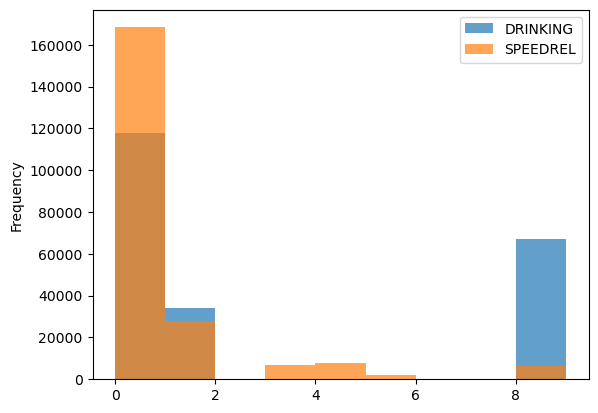

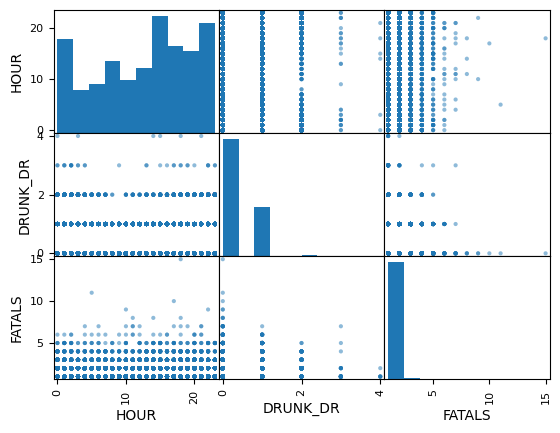

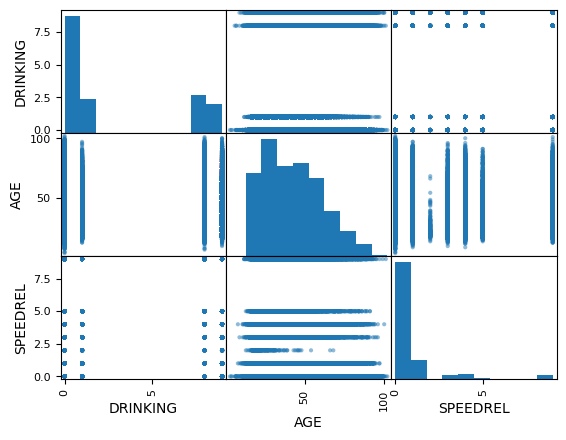

In [3]:
drivers.plot(kind="hist", y=["DRINKING", "SPEEDREL"], bins=9, alpha=0.7)
plt.show()
pd.plotting.scatter_matrix(accidents[["HOUR", "DRUNK_DR", "FATALS"]])
plt.show()
pd.plotting.scatter_matrix(drivers[["DRINKING", "AGE", "SPEEDREL"]])
plt.show()

## Patterns and correlations

After a first look, compare related parts of the data closely. For sequential (time-indexed) data, plot the columns as lines against the index, then make a scatter plot of one column against the other (`kind="scatter"` needs both `x` and `y`) to see correlation independent of the index. Small numbers of entries can be treated as categorical and shown as a bar chart; horizontal bars (`kind="barh"`) are usually easier to compare than vertical ones, and `plt.tight_layout()` makes room for long labels.

> **Achtung!** While searching for patterns, always ask whether the data makes sense and is trustworthy, and what lurking variables could have influenced how it was gathered. Be careful about drawing conclusions from sensitive or questionable data.

## Problem 2: Trends with fatalities

> **Problem 2.** Using the accident data from the previous problem, identify if a trend exists between `FATALS` and the following variables:
> 1. `WEATHER`
> 2. `DRINKING`
> 3. `SP`
>
> Support each claim with a clear, labeled visualization and a short description of how the visualization supports your claim.

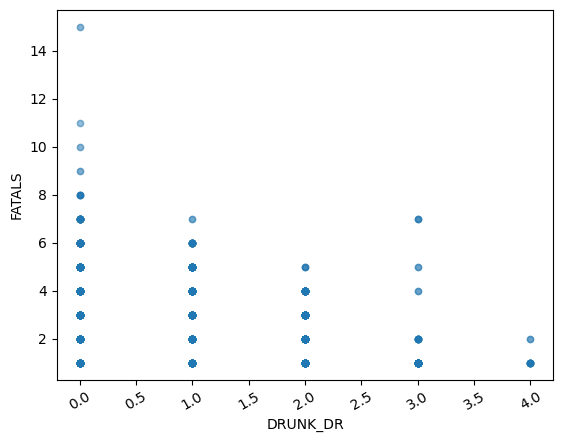

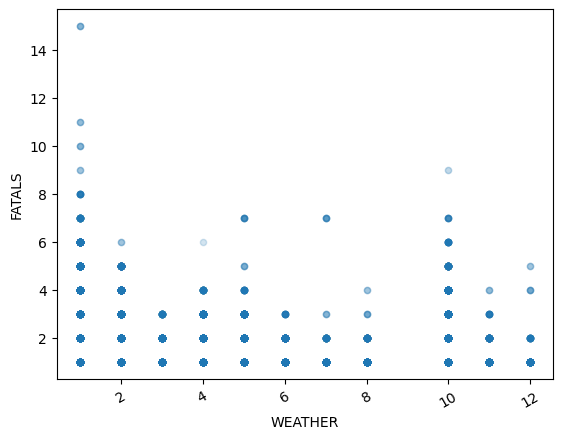

In [4]:
df1 = pd.merge(accidents, drivers, on="ST_CASE")[["ST_CASE", "WEATHER", "SP", "DRINKING", "FATALS", "DRUNK_DR"]]
df1.plot(kind="scatter", x="DRUNK_DR", y="FATALS", alpha=.1, rot=30)
plt.show()
df1[df1.WEATHER<90].plot(kind="scatter", x="WEATHER", y="FATALS", alpha=.1, rot=30)
plt.show()

## Distributional visualizations

Histograms show the distribution of one column, but several overlaid histograms are hard to read. A **box plot** shows the five-number summary (minimum, first quartile, median, third quartile, maximum) and is better for comparing related distributions, though as a summary it hides things like how many points are in each.

A scatter plot samples the joint distribution of two columns, and with many points it becomes an uninformative blob. A **hexbin** plot bins the plane into hexagons and colors each by its count, a 2-D histogram. As with histogram bins, choose `gridsize` with care: a large `gridsize` gives many small bins, a small one fewer, larger bins.

## Problem 3: Distributions

> **Problem 3.** Using distributional visualizations, display a distributional visualization, and provide a brief description and analysis on the following distributions:
> 1. The distribution of accidents across the United States
> 2. The distribution of age in all accidents
> 3. The distribution of fatalities by the hour which the accident occurs
>
> As usual, all plots should be labeled and easy to read.

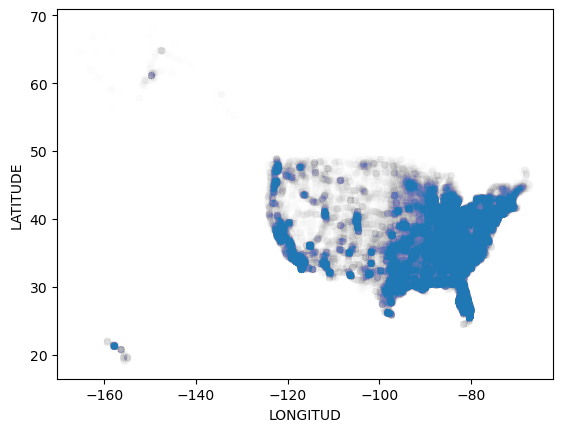

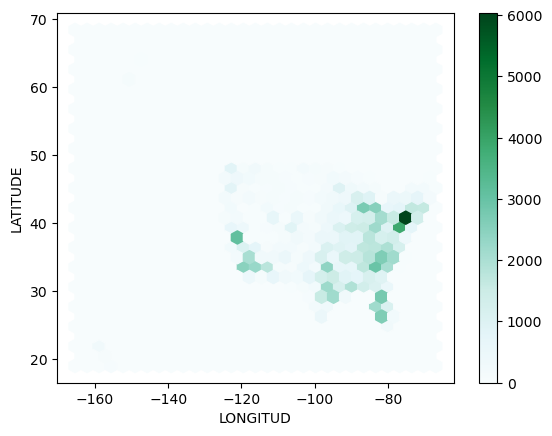

In [5]:
accidents.plot(kind="scatter", x="LONGITUD", y="LATITUDE", alpha=0.002)
plt.show()
accidents.plot(kind="hexbin", x="LONGITUD", y="LATITUDE", gridsize=30)  # [compat] kind names are case-sensitive now
plt.show()

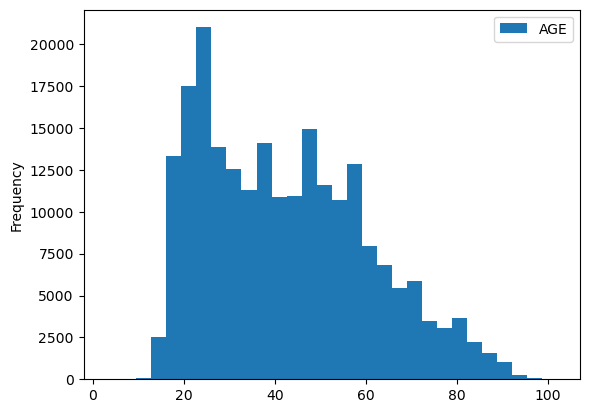

In [6]:
drivers.plot(kind="hist", y="AGE", bins=30)
plt.show()

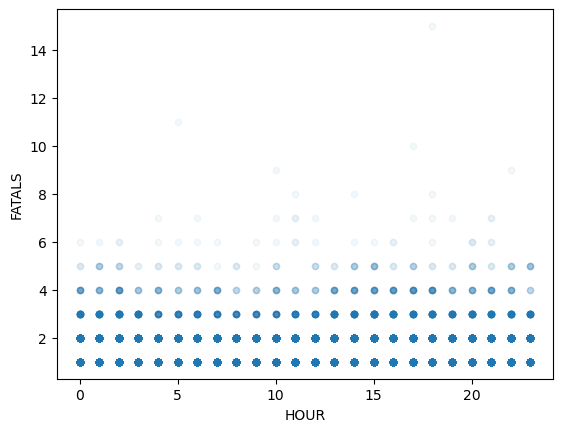

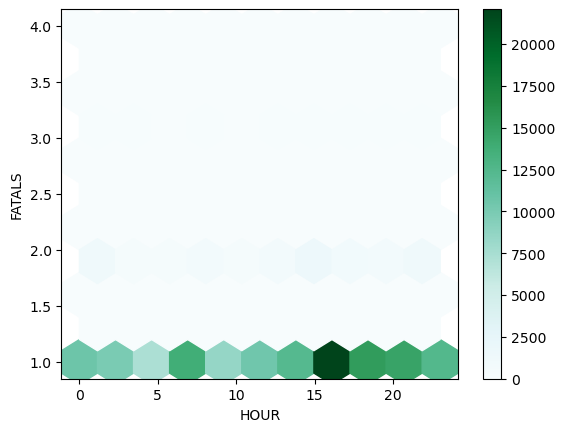

In [7]:
accidents.plot(kind="scatter", x="HOUR", y="FATALS", alpha=0.05)
plt.show()
accidents[accidents.FATALS < 5].plot(kind="hexbin", x="HOUR", y="FATALS", gridsize=10)  # [compat] kind names are case-sensitive now
plt.show()

In [8]:
accidents.max()

ST_CASE     560137.000000
STATE           56.000000
LATITUDE        68.433764
LONGITUD       -66.993169
HOUR            23.000000
DAY             31.000000
MONTH           12.000000
YEAR          2014.000000
DRUNK_DR         4.000000
WEATHER         98.000000
SP               1.000000
FATALS          15.000000
dtype: float64

## Principles of good data visualization

A figure should explain its data on its own: a title, axis labels **with units**, a legend where needed, and the **source** of the data. Leaving the source out is plagiarism. `pydataset`'s `data(name, show_doc=True)` gives a data set's description, units and citation; override pandas' automatic axis labels with `plt.xlabel()`/`plt.ylabel()`, and add a source line with `plt.text()` or `plt.annotate()` (or a caption under the figure).

> **Achtung!** Visualizations can carry the biases of whoever makes them and can be intentionally misleading, e.g. by showing an unrepresentative subset of the data or by misconstrued axes. Every visualizer is responsible for representing the data informatively and accurately.

## Problem 4: Road accident deaths

> **Problem 4.** The `pydataset` module contains numerous data sets, each stored as a pandas `DataFrame`. Read data on road accident deaths in the United States using the data set `road` in the `pydataset` module. Using this data, answer the following questions:
> 1. Does higher population density indicate higher fuel consumption?
> 2. Does a correlation exist between number of drivers and number of deaths in a state?
> 3. Does the temperature of a state in January affect its population density?
>
> Support each claim with a visualization and make sure the visualizations are clearly labeled and easy to understand. Include any citations provided by the data set.
>
> (Hint: Consider how outliers may be skewing the data.)

In [9]:
# [compat] pydataset is not installed here, so the "road" data set (R's MASS::road)
# is rebuilt inline from the table my original run printed.
# from pydataset import data
# road = data("road")
road = pd.DataFrame({
    "deaths": [968, 43, 588, 640, 4743, 566, 325, 118, 115, 1545, 1302, 262, 2207, 1410, 833, 669, 911, 1037, 1196, 616, 766, 2120, 841, 648, 1289, 259],
    "drivers": [158, 11, 91, 92, 952, 109, 167, 30, 35, 298, 203, 41, 544, 254, 150, 136, 147, 146, 46, 157, 255, 403, 189, 85, 234, 38],
    "popden": [64.0, 0.4, 12.0, 34.0, 100.0, 17.0, 518.0, 226.0, 12524.0, 91.0, 68.0, 8.1, 180.0, 129.0, 49.0, 27.0, 76.0, 72.0, 31.0, 314.0, 655.0, 137.0, 43.0, 46.0, 63.0, 4.6],
    "rural": [66.0, 5.9, 33.0, 73.0, 118.0, 73.0, 5.1, 3.4, 0.0, 57.0, 83.0, 40.0, 102.0, 89.0, 100.0, 124.0, 65.0, 40.0, 19.0, 29.0, 17.0, 95.0, 110.0, 59.0, 100.0, 72.0],
    "temp": [62, 30, 64, 51, 65, 42, 37, 41, 44, 67, 54, 36, 33, 37, 30, 42, 44, 65, 30, 44, 37, 33, 22, 57, 40, 29],
    "fuel": [119.0, 6.2, 65.0, 74.0, 105.0, 78.0, 95.0, 20.0, 23.0, 216.0, 162.0, 29.0, 350.0, 196.0, 109.0, 94.0, 104.0, 109.0, 37.0, 113.0, 166.0, 306.0, 132.0, 77.0, 180.0, 31.0],
}, index=["Alabama", "Alaska", "Arizona", "Arkanas", "Calif", "Colo", "Conn", "Dela", "DC", "Florida", "Georgia", "Idaho", "Ill", "Ind", "Iowa", "Kansas", "Kent", "Louis", "Maine", "Maryl", "Mass", "Mich", "Minn", "Miss", "Mo", "Mont"])
road

,deaths,drivers,popden,rural,temp,fuel
Alabama,968,158,64.0,66.0,62,119.0
Alaska,43,11,0.4,5.9,30,6.2
Arizona,588,91,12.0,33.0,64,65.0
Arkanas,640,92,34.0,73.0,51,74.0
Calif,4743,952,100.0,118.0,65,105.0
Colo,566,109,17.0,73.0,42,78.0
Conn,325,167,518.0,5.1,37,95.0
Dela,118,30,226.0,3.4,41,20.0
DC,115,35,12524.0,0.0,44,23.0
Florida,1545,298,91.0,57.0,67,216.0


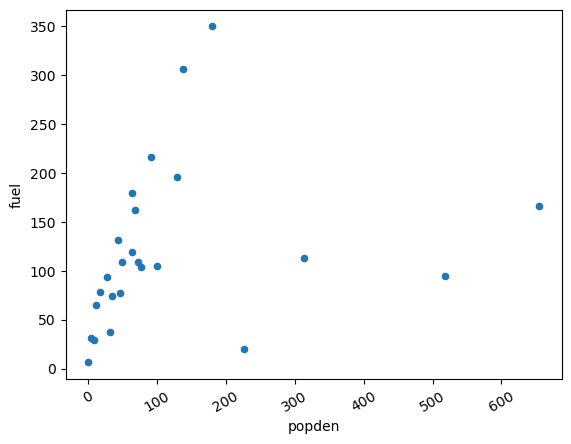

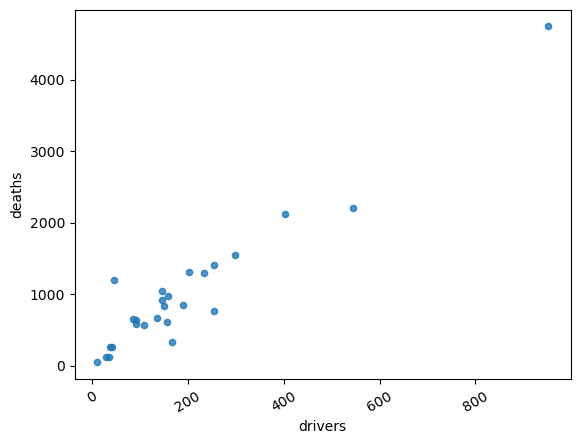

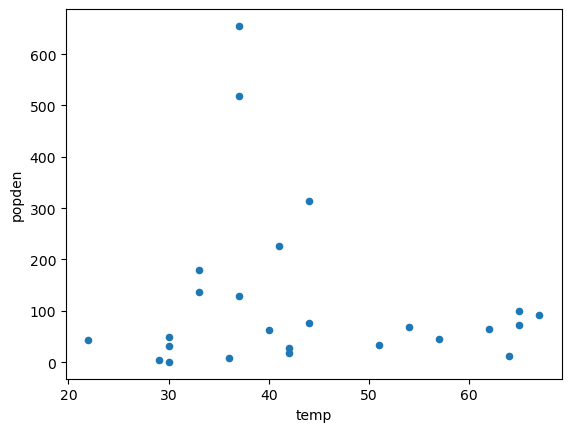

In [10]:
# We leave out the outlier DC since it makes it impossible to visualize
road[road.popden < 10000].plot(kind="scatter", x="popden", y="fuel", alpha=1, rot=30)
plt.show()
road.plot(kind="scatter", x="drivers", y="deaths", alpha=0.8, rot=30)
plt.show()
road[road.popden < 10000].plot(kind="scatter", x="temp", y="popden")
plt.show()

1. Does higher population density indicate higher fuel consumption?

In general, it seems so, but there seem to be one trend between 0 < popden < 200 and another for popden > 200

2. Does a correlation exist between number of drivers and number of deaths in a state?

Definitely yes. It's a linear relationship

3. Does the temperature of a state in January affect its population density?

No. From the data, we can see that they are random.

In [11]:
road[road.popden > 10000]

,deaths,drivers,popden,rural,temp,fuel
DC,115,35,12524.0,0.0,44,23.0


## Problem 5: New York City crime

> **Problem 5.** The file `new_york_crime_clean.csv` contains data on New York City crimes and felonies from 2000-2017 taken from https://www1.nyc.gov/site/nypd/stats/crime-statistics/historical.page. Use this data to answer the following questions and give visualizations supporting each claim:
> 1. What are the most common and least common crimes?
> 2. Does a trend exist between robbery and drug felonies? If so, what is the trend?
> 3. Which crimes have had the largest distributions?
>
> Use a different style of visualization for each question. Make sure that each plot is well labeled and contains citations.
>
> (Hint: Use `plt.axis('scaled')` or `plt.axis('square')` to make sure x- and y-axis are the same.)

In [12]:
nycrimes = pd.read_csv("new_york_crime_clean.csv", index_col=0)
nycrimes

,MURDER & NON-NEGL. MANSLAUGHTER,RAPE,ROBBERY,FELONY ASSAULT,BURGLARY,GRAND LARCENY,GRAND LARCENY OF MOTOR VEHICLE,FELONY POSSESSION OF STOLEN PROPERTY,FORGERY/THEFT_FRAUD/IDENTITY THEFT,ARSON,FELONY SEX CRIMES (3),FELONY DANGEROUS DRUGS (1),FELONY DANGEROUS WEAPONS (2),FEL. CRIMINAL MISCHIEF & RELATED OFFENSES,OTHER FELONIES (4)
OFFENSE,,,,,,,,,,,,,,,
2000,673,2068,32562,25924,38352,49631,35442,2194,5714,3189,1839,38088,2958,12934,13945
2001,649,1981,28202,23453,32763,46329,29531,2114,5594,2681,1831,30743,3030,16026,13059
2002,587,2144,27229,21147,31275,45771,26656,1976,5859,1902,1513,29692,2804,13291,13956
2003,597,2070,25989,19139,29110,46751,23413,1545,8112,1492,1295,24076,2511,8400,13786
2004,570,1905,24373,18622,26976,48763,20884,1358,12984,1789,1263,25824,2987,8074,12454
2005,539,1858,24722,17750,24117,48243,18246,1250,12896,1831,1162,27391,3748,7776,11800
2006,596,1525,23739,17309,23143,46625,15745,1175,12579,1679,1096,29516,4315,7605,11063
2007,496,1351,21809,17493,21762,44924,13174,1073,12075,1527,1031,31459,5004,7090,11699
2008,523,1299,22401,16284,20725,44242,12482,1016,12216,1896,909,28936,5263,7003,11719


In [13]:
nycrimes.describe()

,MURDER & NON-NEGL. MANSLAUGHTER,RAPE,ROBBERY,FELONY ASSAULT,BURGLARY,GRAND LARCENY,GRAND LARCENY OF MOTOR VEHICLE,FELONY POSSESSION OF STOLEN PROPERTY,FORGERY/THEFT_FRAUD/IDENTITY THEFT,ARSON,FELONY SEX CRIMES (3),FELONY DANGEROUS DRUGS (1),FELONY DANGEROUS WEAPONS (2),FEL. CRIMINAL MISCHIEF & RELATED OFFENSES,OTHER FELONIES (4)
count,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
mean,489.888889,1594.388889,21723.777778,19465.888889,22140.722222,44464.222222,14909.888889,1188.500000,9942.944444,1574.666667,1243.166667,24203.944444,4384.277778,8829.944444,12702.611111
std,118.787942,311.384600,4883.438236,2443.798415,7127.897700,3300.467481,8891.651993,475.020774,2345.634606,612.574605,270.493938,6751.431051,1082.615178,2739.346454,1048.688769
min,292.000000,1205.000000,13956.000000,16284.000000,12083.000000,37835.000000,5676.000000,689.000000,5594.000000,680.000000,909.000000,13348.000000,2511.000000,6006.000000,11063.000000
25%,368.750000,1374.250000,18732.750000,17557.250000,17721.750000,43328.000000,7771.250000,833.250000,9499.750000,1217.000000,1058.000000,19598.250000,3209.500000,7024.750000,11739.250000
50%,519.000000,1441.500000,20976.500000,19260.000000,20077.500000,44601.500000,11576.000000,1046.000000,10144.000000,1483.000000,1157.000000,24950.000000,4845.500000,7925.000000,12734.000000
75%,582.750000,1893.250000,24634.750000,20290.250000,26261.250000,46551.000000,20224.500000,1331.000000,11826.000000,1820.500000,1359.250000,29371.000000,5125.500000,9787.750000,13715.750000
max,673.000000,2144.000000,32562.000000,25924.000000,38352.000000,49631.000000,35442.000000,2194.000000,12984.000000,3189.000000,1839.000000,38088.000000,5952.000000,16026.000000,14217.000000


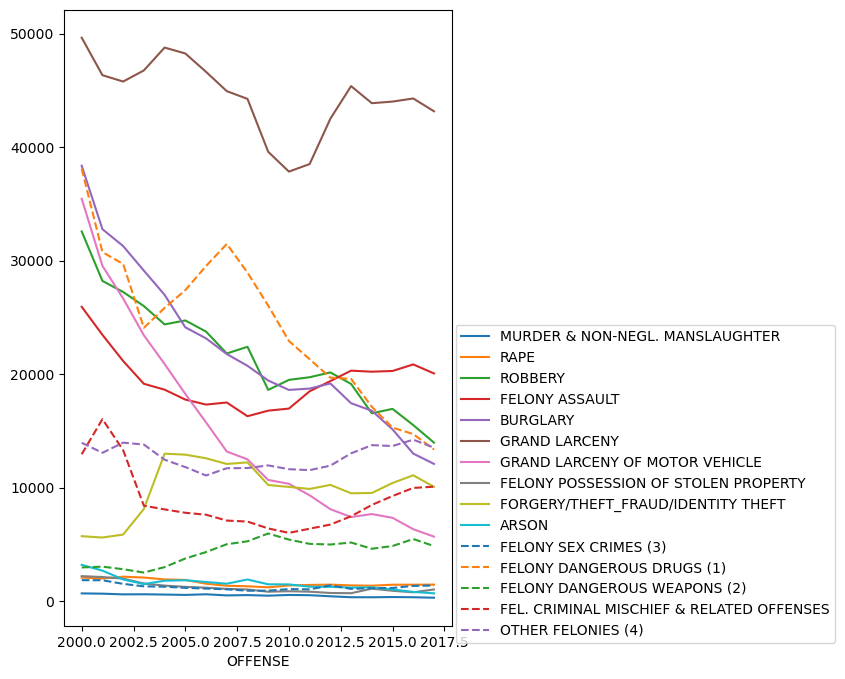

In [14]:
style_list = ['-'] * 10 + ['--'] * 5
nycrimes.plot(y=list(nycrimes), style=style_list, figsize=(5,8))
plt.legend(loc='upper center', bbox_to_anchor=(1.50, 0.5))
plt.show()

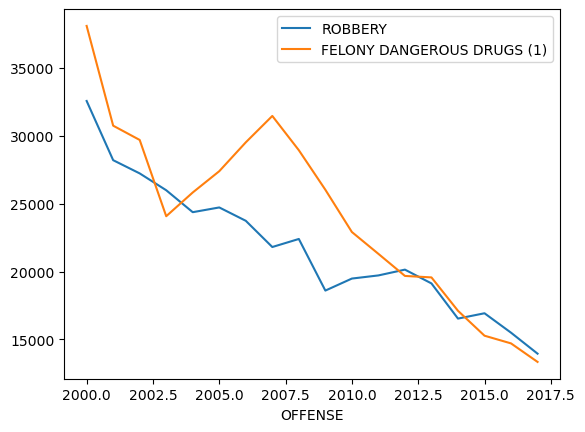

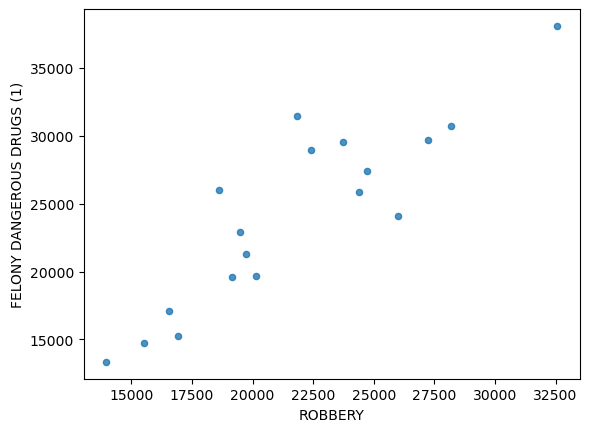

In [15]:
nycrimes.plot(y=["ROBBERY", "FELONY DANGEROUS DRUGS (1)"])
plt.show()
nycrimes.plot(kind="scatter", x="ROBBERY", y="FELONY DANGEROUS DRUGS (1)", alpha=.8)
plt.show()

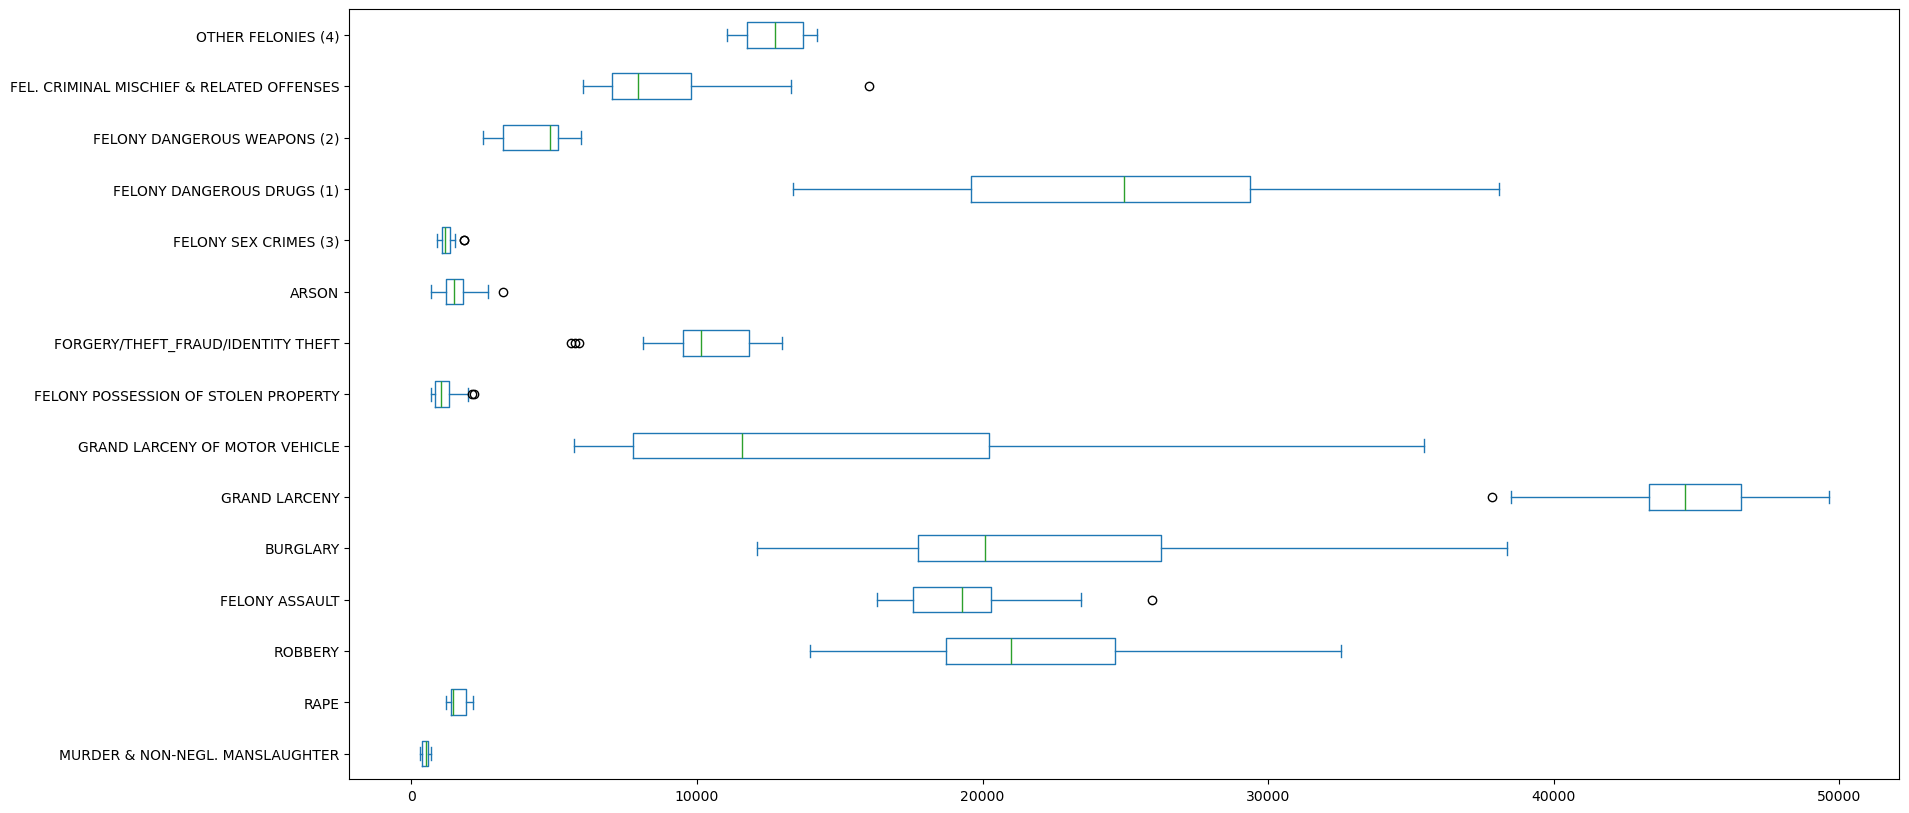

In [16]:
nycrimes.plot(kind="box", y=list(nycrimes), vert=False, figsize=(20,10))
plt.show()

1. What are the most common and least common crimes?

Most common: Grand Larceny
Least common: Murder / manslaughter

2. Does a trend exist between robbery and drug felonies? If so, what is the trend?

Yes. It almost seems like a 1 to 1 correlation, and they have both been declining over the years

3. Which crimes have had the largest distributions?

Grand larceny of motor vehicle, since it seems to have the largest difference between its minimum and the maximum